# 03 — Model Comparison

Сравнение всех моделей по prediction CSV из `main.py`.

**Требуется**: сначала запустить `main.py`

In [1]:
import sys
ROOT = r'D:\clode9'
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
from thesis_app.notebook_helpers import apply_thesis_plot_style, preferred_xgb_label, best_ml_model_name, significance_stars, interpretation_text
apply_thesis_plot_style()


## Interpretation focus
Use this notebook to answer which models forecast intermarket dependency most reliably across assets and rolling windows. For the thesis text, emphasize consistency across experiments, not only the single best score.

In [2]:
import sys, os
ROOT = r'D:\clode9'
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from glob import glob
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from thesis_app.pipeline import load_config, build_paths, metrics_to_latex

%matplotlib inline
plt.rcParams['figure.dpi'] = 110

cfg   = load_config(os.path.join(ROOT, 'config.yaml'))
paths = build_paths(cfg['base_dir'])
print('Predictions dir:', paths.predictions)


Predictions dir: D:/clode9\outputs\predictions


In [3]:
# ── Load all prediction CSVs ─────────────────────────────────
csv_files = sorted(glob(os.path.join(paths.predictions, '*_predictions.csv')))
print(f'Found {len(csv_files)} prediction files')

experiments = {}
for f in csv_files:
    name = os.path.basename(f).replace('_predictions.csv', '')
    experiments[name] = pd.read_csv(f, index_col=0, parse_dates=True)

list(experiments.keys())


Found 24 prediction files


['corr_BTC-USD_ETH-USD_w14_fisher_z',
 'corr_BTC-USD_ETH-USD_w30_fisher_z',
 'corr_BTC-USD_ETH-USD_w60_fisher_z',
 'corr_BTC-USD_ETH-USD_w90_fisher_z',
 'corr_BTC-USD_GLD_w14_fisher_z',
 'corr_BTC-USD_GLD_w30_fisher_z',
 'corr_BTC-USD_GLD_w60_fisher_z',
 'corr_BTC-USD_GLD_w90_fisher_z',
 'corr_BTC-USD_SLV_w14_fisher_z',
 'corr_BTC-USD_SLV_w30_fisher_z',
 'corr_BTC-USD_SLV_w60_fisher_z',
 'corr_BTC-USD_SLV_w90_fisher_z',
 'corr_BTC-USD_UUP_w14_fisher_z',
 'corr_BTC-USD_UUP_w30_fisher_z',
 'corr_BTC-USD_UUP_w60_fisher_z',
 'corr_BTC-USD_UUP_w90_fisher_z',
 'corr_BTC-USD_^GSPC_w14_fisher_z',
 'corr_BTC-USD_^GSPC_w30_fisher_z',
 'corr_BTC-USD_^GSPC_w60_fisher_z',
 'corr_BTC-USD_^GSPC_w90_fisher_z',
 'corr_BTC-USD_^IXIC_w14_fisher_z',
 'corr_BTC-USD_^IXIC_w30_fisher_z',
 'corr_BTC-USD_^IXIC_w60_fisher_z',
 'corr_BTC-USD_^IXIC_w90_fisher_z']

In [4]:
# ── Metrics for all experiments ───────────────────────────────
rows = []
for key, df in experiments.items():
    y_true = df['y_true'].dropna()
    parts = key.split('_w')
    dep_part = parts[0]
    w_space_parts = parts[1].split('_', 1) if len(parts) > 1 else ['0', 'unknown']
    window = int(w_space_parts[0]) if w_space_parts[0].isdigit() else 0
    space = w_space_parts[1] if len(w_space_parts) > 1 else 'unknown'

    for model in [c for c in df.columns if c != 'y_true']:
        pred = df[model].dropna()
        common = y_true.index.intersection(pred.index)
        if len(common) < 50:
            continue
        yt = y_true.loc[common].values
        yp = pred.loc[common].values
        rows.append({
            'experiment': key, 'dependency': dep_part, 'window': window,
            'space': space, 'model': model,
            'MAE':  float(mean_absolute_error(yt, yp)),
            'RMSE': float(np.sqrt(mean_squared_error(yt, yp))),
            'R2':   float(r2_score(yt, yp)),
            'n':    len(common),
        })

metrics = pd.DataFrame(rows)
print(f'Total rows: {len(metrics)}')
metrics.head()


Total rows: 192


,experiment,dependency,window,space,model,MAE,RMSE,R2,n
0,corr_BTC-USD_ETH-USD_w14_fisher_z,corr_BTC-USD_ETH-USD,14,fisher_z,Naive_Last,0.098571,0.158029,0.879419,2190
1,corr_BTC-USD_ETH-USD_w14_fisher_z,corr_BTC-USD_ETH-USD,14,fisher_z,AR1,0.101123,0.155936,0.882592,2190
2,corr_BTC-USD_ETH-USD_w14_fisher_z,corr_BTC-USD_ETH-USD,14,fisher_z,ElasticNet,0.146515,0.203131,0.800769,2190
3,corr_BTC-USD_ETH-USD_w14_fisher_z,corr_BTC-USD_ETH-USD,14,fisher_z,Ridge,0.145713,0.202229,0.802534,2190
4,corr_BTC-USD_ETH-USD_w14_fisher_z,corr_BTC-USD_ETH-USD,14,fisher_z,RF,0.155599,0.213296,0.780329,2190


In [5]:
# ── Best model per experiment ────────────────────────
BASELINES = ('Naive_Last', 'AR1', 'DCC_GARCH')
ML_MODELS = [m for m in metrics['model'].unique() if m not in BASELINES]
ml_metrics = metrics[metrics['model'].isin(ML_MODELS)]
best_per_exp = ml_metrics.loc[ml_metrics.groupby('experiment')['RMSE'].idxmin()]
print(best_per_exp[['dependency','window','model','RMSE','R2']].to_string(index=False))


          dependency  window      model     RMSE       R2
corr_BTC-USD_ETH-USD      14      Ridge 0.202229 0.802534
corr_BTC-USD_ETH-USD      30      Ridge 0.100061 0.923053
corr_BTC-USD_ETH-USD      60      Ridge 0.052308 0.969707
corr_BTC-USD_ETH-USD      90      Ridge 0.036408 0.980911
    corr_BTC-USD_GLD      14      Ridge 0.192270 0.742413
    corr_BTC-USD_GLD      30 ElasticNet 0.091917 0.876377
    corr_BTC-USD_GLD      60      Ridge 0.048350 0.941056
    corr_BTC-USD_GLD      90      Ridge 0.032970 0.962624
    corr_BTC-USD_SLV      14      Ridge 0.194079 0.721096
    corr_BTC-USD_SLV      30      Ridge 0.087845 0.881784
    corr_BTC-USD_SLV      60      Ridge 0.045588 0.944566
    corr_BTC-USD_SLV      90      Ridge 0.030641 0.965362
    corr_BTC-USD_UUP      14      Ridge 0.199377 0.768149
    corr_BTC-USD_UUP      30 ElasticNet 0.094799 0.891038
    corr_BTC-USD_UUP      60      Ridge 0.047939 0.949058
    corr_BTC-USD_UUP      90      Ridge 0.031972 0.968261
  corr_BTC-USD

RMSE table (corr_BTC-USD_^GSPC):
window          14      30      60      90
model                                     
AR1         0.1429  0.0647  0.0320  0.0220
DCC_GARCH   0.3294  0.1981  0.1294  0.1065
ElasticNet  0.1918  0.0897  0.0460  0.0329
GBM         0.2047  0.1001  0.0554  0.0405
Naive_Last  0.1450  0.0650  0.0320  0.0221
RF          0.2016  0.0972  0.0561  0.0381
Ridge       0.1914  0.0890  0.0450  0.0318
XGB_GPU     0.2107  0.1010  0.0569  0.0422


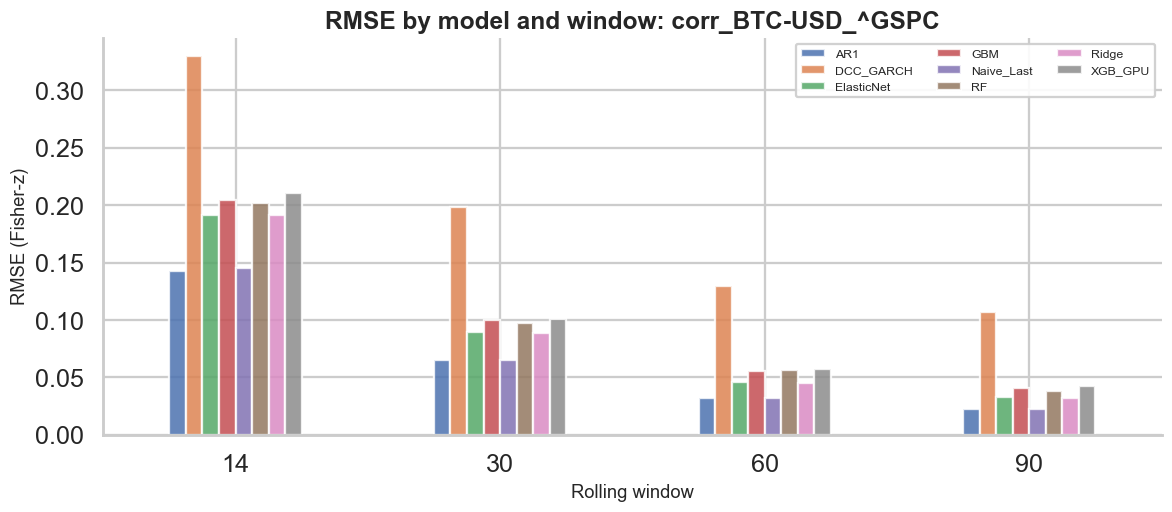

In [6]:
# ── RMSE comparison for one pair ───────────────────────────────
DEP = 'corr_BTC-USD_^GSPC'
sub = metrics[metrics['dependency'] == DEP].copy()
pivot = sub.pivot_table(index='model', columns='window', values='RMSE')
print(f'RMSE table ({DEP}):')
print(pivot.round(4))

fig, ax = plt.subplots(figsize=(11, 5))
pivot.T.plot(kind='bar', ax=ax, alpha=0.85)
ax.set_title(f'RMSE by model and window: {DEP}')
ax.set_xlabel('Rolling window')
ax.set_ylabel('RMSE (Fisher-z)')
ax.legend(ncol=3, fontsize=8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(paths.figures, f'model_rmse_comparison.png'), dpi=130)
plt.show()


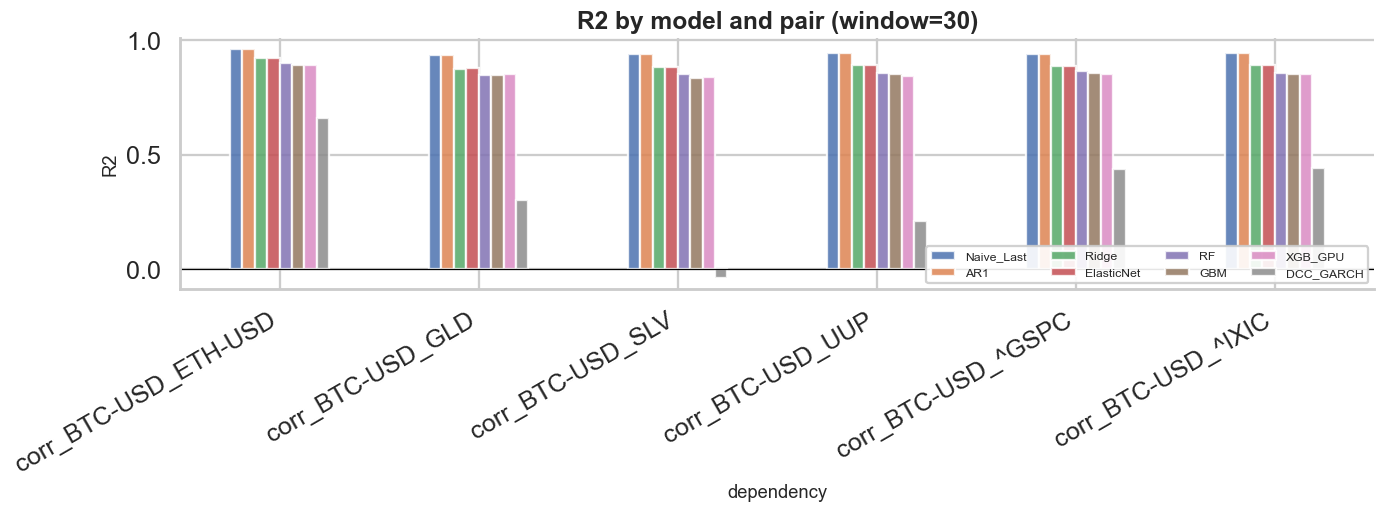

Interpretation: higher R2 indicates stronger practical usefulness in the out-of-sample setting.


In [7]:
# ── R2 comparison, window=30 ─────────────────────────────────────
W = 30
model_order = [m for m in ['Naive_Last', 'AR1', 'Ridge', 'ElasticNet', 'RF', 'GBM', 'XGB_GPU', 'XGB_CPU', 'DCC_GARCH'] if m in metrics['model'].unique()]
available = [m for m in model_order if m in metrics['model'].unique()]

sub30 = metrics[metrics['window'] == W].copy()
pivot_r2 = sub30.pivot_table(index='dependency', columns='model', values='R2')[available]

fig, ax = plt.subplots(figsize=(13, 5))
pivot_r2.plot(kind='bar', ax=ax, alpha=0.85)
ax.axhline(0, color='black', lw=0.8)
ax.set_title(f'R2 by model and pair (window={W})')
ax.set_ylabel('R2')
ax.legend(ncol=4, fontsize=8, loc='lower right')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(paths.figures, f'model_r2_comparison_w{W}.png'), dpi=130)
plt.show()

print(interpretation_text('R2', higher_is_better=True))


In [8]:
# ── Overall ranking by mean RMSE ───────────────────────────────
ranking = metrics.groupby('model')[['RMSE','MAE','R2']].mean().sort_values('RMSE').round(4)
print('Mean metrics across all experiments:')
print(ranking.to_string())

metrics.to_csv(os.path.join(paths.results, 'metrics_all_models.csv'), index=False)
ranking.to_csv(os.path.join(paths.results, 'model_ranking.csv'))
print('Saved.')


Mean metrics across all experiments:
              RMSE     MAE      R2
model                             
AR1         0.0665  0.0405  0.9423
Naive_Last  0.0672  0.0395  0.9411
Ridge       0.0914  0.0636  0.8917
ElasticNet  0.0921  0.0643  0.8902
RF          0.1009  0.0709  0.8694
GBM         0.1035  0.0732  0.8630
XGB_GPU     0.1043  0.0744  0.8605
DCC_GARCH   0.2147  0.1687  0.3814
Saved.


     model  mean_improvement_%  n
     Ridge              -39.02 24
ElasticNet              -40.95 24
        RF              -60.12 24
       GBM              -64.48 24
   XGB_GPU              -65.99 24
 DCC_GARCH             -303.07 24


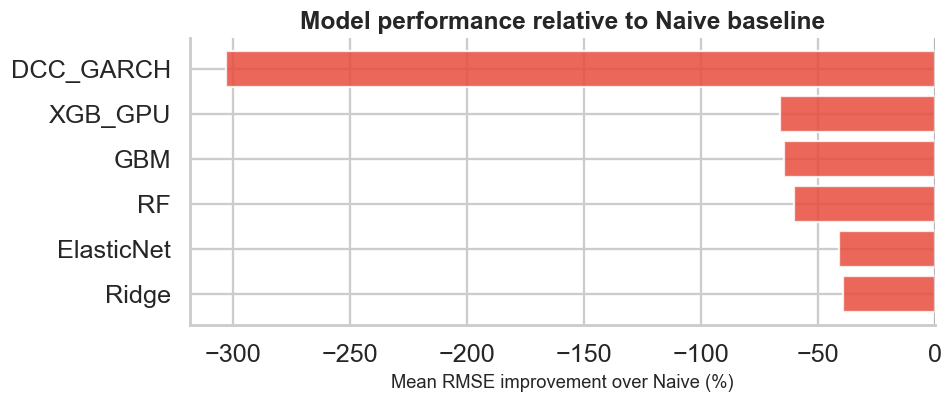

In [9]:
# ── Improvement over Naive baseline ─────────────────────────────────
naive_rmse = metrics[metrics['model'] == 'Naive_Last'].set_index('experiment')['RMSE']
improvement = []
for model in ML_MODELS + ['DCC_GARCH']:
    sub_m = metrics[metrics['model'] == model].set_index('experiment')
    common = sub_m.index.intersection(naive_rmse.index)
    if len(common) == 0:
        continue
    rel = ((naive_rmse[common] - sub_m.loc[common, 'RMSE']) / naive_rmse[common] * 100)
    improvement.append({'model': model, 'mean_improvement_%': rel.mean(), 'n': len(common)})

imp_df = pd.DataFrame(improvement).sort_values('mean_improvement_%', ascending=False)
print(imp_df.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#2ecc71' if v > 0 else '#e74c3c' for v in imp_df['mean_improvement_%']]
ax.barh(imp_df['model'], imp_df['mean_improvement_%'], color=colors, alpha=0.85)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Mean RMSE improvement over Naive (%)')
ax.set_title('Model performance relative to Naive baseline')
plt.tight_layout()
plt.savefig(os.path.join(paths.figures, 'model_improvement_over_naive.png'), dpi=130)
plt.show()


In [10]:
# ── LaTeX table ───────────────────────────────────────────────────
metrics_for_latex = metrics.rename(columns={'space': 'target_space'}).copy()
metrics_for_latex['dependency'] = metrics_for_latex['dependency'].str.replace('corr_', '', regex=False)
tex_path = os.path.join(paths.tables, 'model_comparison_full.tex')
metrics_to_latex(
    metrics_for_latex.sort_values(['dependency', 'window', 'RMSE']).head(80),
    tex_path,
    caption='Out-of-sample forecasting metrics (Fisher-z space).',
    label='tab:model_comparison',
)
print(f'LaTeX saved: {tex_path}')
print('Model comparison complete.')


LaTeX saved: D:/clode9\outputs\tables\model_comparison_full.tex
Model comparison complete.
